# Mansi Devganiya
# Track: Data Analytics
# Task: Level 1 - Cleaning Data

**Oasis Infobyte | Summer Internship Programme (SIP)**

## Objective
To take a deliberately messy medical dataset and transform it, step by step, into a clean and analysis-ready dataset, documenting every decision.

**Dataset:** Medical Students Dataset (Kaggle), 200,000 rows and 13 columns
**Tools:** Python, pandas, numpy, matplotlib, seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

## 1. Data Loading and Initial Inspection
The dataset is loaded and an untouched copy (raw) is saved. It will be used at the end for the before vs after comparison.

In [2]:
df = pd.read_csv("dirty_dataset.csv")
raw = df.copy()   # untouched copy, used later for the before vs after comparison

print("Shape:", df.shape)
df.head()

Shape: (200000, 13)


,Student ID,Age,Gender,Height,Weight,Blood Type,BMI,Temperature,Heart Rate,Blood Pressure,Cholesterol,Diabetes,Smoking
0,1.0,18.0,Female,161.777924,72.354947,O,27.645835,NaN,95.0,109.0,203.0,No,NaN
1,2.0,NaN,Male,152.069157,47.630941,B,NaN,98.714977,93.0,104.0,163.0,No,No
2,3.0,32.0,Female,182.537664,55.741083,A,16.729017,98.260293,76.0,130.0,216.0,Yes,No
3,NaN,30.0,Male,182.112867,63.332207,B,19.096042,98.839605,99.0,112.0,141.0,No,Yes
4,5.0,23.0,Female,NaN,46.234173,O,NaN,98.480008,95.0,NaN,231.0,No,No


## 2. Data Quality Report
Before cleaning anything, we measure the problems: null values, duplicates, data types and value ranges.

In [3]:
report = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Null count": df.isnull().sum(),
    "Null %": (df.isnull().mean() * 100).round(2),
    "Unique values": df.nunique()
})
display(report)

print("Exact duplicate rows      :", df.duplicated().sum())
print("Rows with at least 1 null :", df.isnull().any(axis=1).sum())
print("Student IDs that repeat   :", df["Student ID"].dropna().duplicated().sum())

,Data type,Null count,Null %,Unique values
Student ID,float64,20000,10.0,98976
Age,float64,20000,10.0,17
Gender,str,20000,10.0,2
Height,float64,20000,10.0,98992
Weight,float64,20000,10.0,99026
Blood Type,str,20000,10.0,4
BMI,float64,20000,10.0,98983
Temperature,float64,20000,10.0,99006
Heart Rate,float64,20000,10.0,40
Blood Pressure,float64,20000,10.0,50


Exact duplicate rows      : 7644
Rows with at least 1 null : 149207
Student IDs that repeat   : 81024


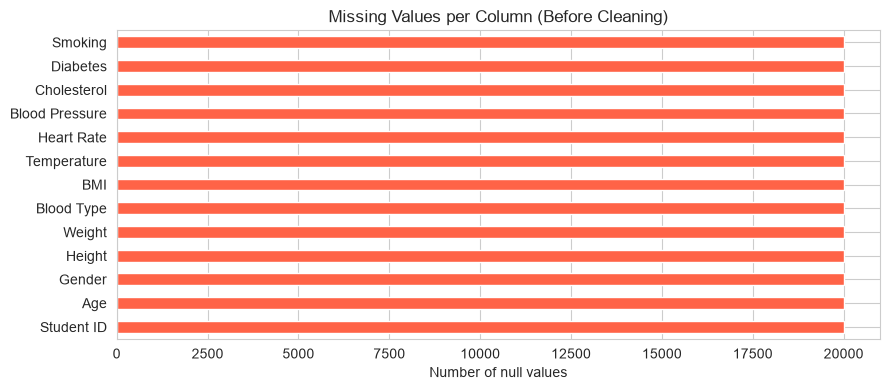

In [4]:
plt.figure(figsize=(9,4))
df.isnull().sum().sort_values().plot(kind="barh", color="tomato")
plt.title("Missing Values per Column (Before Cleaning)")
plt.xlabel("Number of null values")
plt.tight_layout()
plt.show()

In [5]:
print(df.describe().round(2).T[["min", "max", "mean"]])
print()
for col in ["Gender", "Blood Type", "Diabetes", "Smoking"]:
    print(col, "->", df[col].value_counts(dropna=False).to_dict())

                   min        max      mean
Student ID        1.00  100000.00  49974.04
Age              18.00      34.00     26.02
Height          150.00     200.00    174.95
Weight           40.00     100.00     69.97
BMI              10.07      44.36     23.34
Temperature      96.40     100.82     98.60
Heart Rate       60.00      99.00     79.50
Blood Pressure   90.00     139.00    114.56
Cholesterol     120.00     249.00    184.49

Gender -> {'Male': 90005, 'Female': 89995, nan: 20000}
Blood Type -> {'B': 45537, 'O': 45511, 'AB': 44486, 'A': 44466, nan: 20000}
Diabetes -> {'No': 161986, nan: 20000, 'Yes': 18014}
Smoking -> {'No': 143971, 'Yes': 36029, nan: 20000}


**Observations (data quality problems found):**
- The dataset has 200,000 rows and 13 columns.
- **Missing values:** every column has exactly 20,000 nulls (10%), which is 260,000 missing values in total. 149,207 rows have at least one null.
- **Duplicates:** there are 7,644 exact duplicate rows. In addition, 81,024 Student IDs are repeated, so the same student appears in more than one row (these rows are not exact duplicates because the nulls fall in different places).
- **Data types:** Student ID, Age, Heart Rate, Blood Pressure and Cholesterol are stored as float although they are whole numbers.
- **Formatting:** text columns (Gender, Blood Type, Diabetes, Smoking) are already consistent, with no "male / Male / M" type issues. The dataset has no date column.
- **Value ranges:** all values are medically plausible (Age 18-34, Height 150-200 cm, Weight 40-100 kg, Temperature 96.4-100.8 F), so there are no impossible values.

## 3. Outlier Check (Before Cleaning)
Outliers are detected with the IQR method: a value is an outlier if it is below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR.

,IQR outliers
Age,0
Height,0
Weight,0
BMI,186
Temperature,1301
Heart Rate,0
Blood Pressure,0
Cholesterol,0


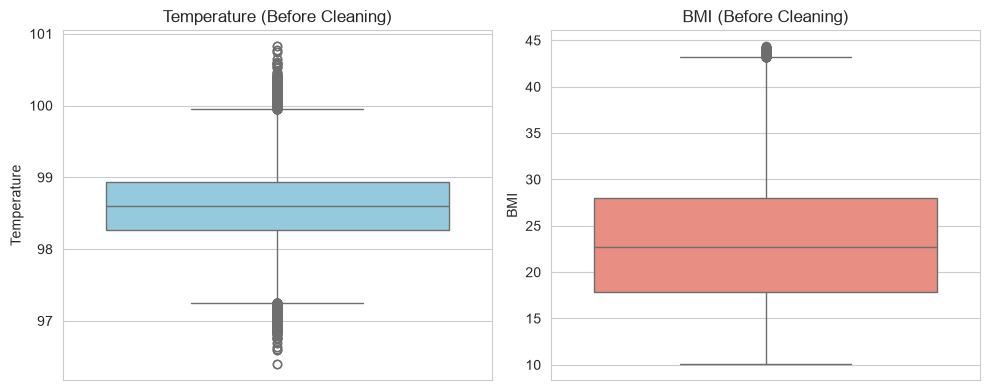

In [6]:
num_cols = ["Age", "Height", "Weight", "BMI", "Temperature",
            "Heart Rate", "Blood Pressure", "Cholesterol"]
cat_cols = ["Gender", "Blood Type", "Diabetes", "Smoking"]

def iqr_outliers(data):
    result = {}
    for c in num_cols:
        q1, q3 = data[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        result[c] = int(((data[c] < q1 - 1.5 * iqr) | (data[c] > q3 + 1.5 * iqr)).sum())
    return pd.Series(result, name="IQR outliers")

outliers_before = iqr_outliers(df)
display(outliers_before.to_frame())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df["Temperature"], ax=ax[0], color="skyblue")
ax[0].set_title("Temperature (Before Cleaning)")
sns.boxplot(y=df["BMI"], ax=ax[1], color="salmon")
ax[1].set_title("BMI (Before Cleaning)")
plt.tight_layout()
plt.show()

**Observations:**
- Only two columns have outliers: Temperature (1,301) and BMI (186). All other numeric columns have none.
- The outlying temperatures lie between about 96.4 and 100.8 F, and the outlying BMI values between about 10 and 44. These are unusual but physically possible values, so they need a careful decision (see Step 8).

## 4. Data Cleaning

### Step 1: Standardise text columns
**What:** remove extra spaces and unify capitalisation (Gender, Diabetes, Smoking in Title Case; Blood Type in upper case).
**Why:** values such as "male" and "Male" would otherwise be counted as different categories.
**Result:** 0 values needed changing, so the text columns were already consistent. The step is kept as a safety check.

In [7]:
for col in cat_cols:
    df[col] = df[col].astype("string").str.strip()

for col in ["Gender", "Diabetes", "Smoking"]:
    df[col] = df[col].str.title()
df["Blood Type"] = df["Blood Type"].str.upper()

changed = {col: int((raw[col].astype("string") != df[col]).fillna(False).sum()) for col in cat_cols}
print("Values changed by standardisation:", changed)

Values changed by standardisation: {'Gender': 0, 'Blood Type': 0, 'Diabetes': 0, 'Smoking': 0}


### Step 2: Remove exact duplicate rows
**What:** drop rows that are identical in every column.
**Why:** duplicates count the same record twice and distort statistics.
**Result:** 7,644 exact duplicate rows were removed, leaving 192,356 rows.

In [8]:
rows_before = len(df)
df = df.drop_duplicates()
print("Exact duplicate rows removed:", rows_before - len(df))
print("Rows remaining:", len(df))

Exact duplicate rows removed: 7644
Rows remaining: 192356


### Step 3: Drop rows with a missing Student ID
**What:** remove rows where Student ID is null.
**Why:** Student ID is an identifier, so it cannot be estimated with a mean or median, and a row without an ID cannot be matched to a student.
**Result:** 19,891 rows were dropped, leaving 172,465 rows.

In [9]:
null_ids = df["Student ID"].isnull().sum()
df = df.dropna(subset=["Student ID"])
print("Rows dropped (missing Student ID):", null_ids)
print("Rows remaining:", len(df))

Rows dropped (missing Student ID): 19891
Rows remaining: 172465


### Step 4: Combine rows that belong to the same student
**What:** the same Student ID appears in two rows, with nulls in different columns. First we check that the two rows never disagree, then we merge them by keeping the first non-null value of every column.
**Why:** this removes the repeated students and also recovers many missing values for free, without guessing.
**Result:** the check shows no conflicts (every column has at most 1 distinct value per student). 73,489 students appeared in more than one row. After combining, there are 98,976 unique students and 0 duplicate IDs. Total nulls dropped from 260,000 to 31,378.

In [10]:
grouped = df.groupby("Student ID")
other_cols = [c for c in df.columns if c != "Student ID"]

# Check: for the same student, do any columns hold two DIFFERENT values?
conflicts = grouped[other_cols].nunique().max()
print("Max distinct values per student (1 = no conflicts):")
print(conflicts.to_dict())
print("\nStudents appearing in more than one row:", (grouped.size() > 1).sum())

Max distinct values per student (1 = no conflicts):
{'Age': 1, 'Gender': 1, 'Height': 1, 'Weight': 1, 'Blood Type': 1, 'BMI': 1, 'Temperature': 1, 'Heart Rate': 1, 'Blood Pressure': 1, 'Cholesterol': 1, 'Diabetes': 1, 'Smoking': 1}

Students appearing in more than one row: 73489


In [11]:
# Combine: keep the first non-null value of each column for every student
df = grouped.first().reset_index()
print("Shape after combining:", df.shape)
print("Duplicate Student IDs :", df["Student ID"].duplicated().sum())
print("\nNull values per column after combining:")
print(df.isnull().sum().to_dict())

Shape after combining: (98976, 13)
Duplicate Student IDs : 0

Null values per column after combining:
{'Student ID': 0, 'Age': 2668, 'Gender': 2613, 'Height': 2624, 'Weight': 2543, 'Blood Type': 2600, 'BMI': 2609, 'Temperature': 2687, 'Heart Rate': 2713, 'Blood Pressure': 2535, 'Cholesterol': 2603, 'Diabetes': 2552, 'Smoking': 2631}


### Step 5: Recover Height, Weight and BMI using the BMI formula
**What:** BMI = Weight / Height squared (Height in metres). If any one of the three is missing and the other two are known, it is calculated.
**Why:** this is an exact calculation, so it is more reliable than filling with an average. In the data, the formula matches the BMI column almost exactly.
**Result:** 2,233 BMI, 2,189 Weight and 2,248 Height values were recovered. Remaining nulls: Height 376, Weight 354, BMI 376.

In [12]:
height_m = df["Height"] / 100

# BMI = Weight / Height^2  ->  any one of the three can be recovered from the other two
m_bmi = df["BMI"].isnull() & df["Height"].notna() & df["Weight"].notna()
df.loc[m_bmi, "BMI"] = df.loc[m_bmi, "Weight"] / height_m[m_bmi] ** 2

m_weight = df["Weight"].isnull() & df["BMI"].notna() & df["Height"].notna()
df.loc[m_weight, "Weight"] = df.loc[m_weight, "BMI"] * height_m[m_weight] ** 2

m_height = df["Height"].isnull() & df["BMI"].notna() & df["Weight"].notna()
df.loc[m_height, "Height"] = np.sqrt(df.loc[m_height, "Weight"] / df.loc[m_height, "BMI"]) * 100

print("BMI recovered   :", m_bmi.sum())
print("Weight recovered:", m_weight.sum())
print("Height recovered:", m_height.sum())
print("\nNulls still left in Height / Weight / BMI:",
      df[["Height", "Weight", "BMI"]].isnull().sum().to_dict())

BMI recovered   : 2233
Weight recovered: 2189
Height recovered: 2248

Nulls still left in Height / Weight / BMI: {'Height': 376, 'Weight': 354, 'BMI': 376}


### Step 6: Fill the remaining missing values
**Numeric columns: median imputation.** The median is not affected by extreme values, unlike the mean. Medians used: Age 26, Height 174.9 cm, Weight 69.98 kg, Temperature 98.6 F, Heart Rate 80, Blood Pressure 115, Cholesterol 184. For Height and Weight the median is filled first, and then BMI is recalculated from them, so the three columns stay consistent.
**Categorical columns: a new category "Unknown".** In medical data, assuming that a student with a missing Diabetes or Smoking value is "No" could be wrong and misleading. Marking it "Unknown" does not invent information. Counts of Unknown: Gender 2,613, Blood Type 2,600, Diabetes 2,552, Smoking 2,631.
**Result:** 0 null values remain.

In [13]:
# Height and Weight: median first, then recompute BMI so the three stay consistent
hw_missing = df["Height"].isnull() | df["Weight"].isnull()
bmi_missing = df["BMI"].isnull()

for col in ["Height", "Weight"]:
    df[col] = df[col].fillna(df[col].median())

fix = hw_missing | bmi_missing
df.loc[fix, "BMI"] = df.loc[fix, "Weight"] / (df.loc[fix, "Height"] / 100) ** 2

# Remaining numeric columns: median
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Categorical columns: "Unknown" category
for col in cat_cols:
    df[col] = df[col].fillna("Unknown")

print("Total null values left:", df.isnull().sum().sum())

Total null values left: 0


### Step 7: Correct the data types
**What:** Student ID, Age, Heart Rate, Blood Pressure and Cholesterol are converted from float to integer. The four text columns are converted to the category type.
**Why:** whole numbers should not carry decimals, and the category type saves memory and shows the intended meaning of the column.
**Result:** all 13 columns now have the correct data type.

In [14]:
for col in ["Student ID", "Age", "Heart Rate", "Blood Pressure", "Cholesterol"]:
    df[col] = df[col].astype(int)

for col in cat_cols:
    df[col] = df[col].astype("category")

df.dtypes

Student ID           int64
Age                  int64
Gender            category
Height             float64
Weight             float64
Blood Type        category
BMI                float64
Temperature        float64
Heart Rate           int64
Blood Pressure       int64
Cholesterol          int64
Diabetes          category
Smoking           category
dtype: object

### Step 8: Decide what to do with outliers
**Temperature:** retained. The values range from 96.4 to 100.8 F, which is a normal range for human body temperature. A mild fever is real data, not an error.
**BMI:** retained. BMI is calculated exactly from Height and Weight (both within valid ranges), so extreme BMI values are genuine combinations (for example, a tall and light student), not mistakes.
**Other columns:** no outliers were found.
**Why not remove or cap them:** removing real medical values would hide genuine cases and bias the analysis.
**Result:** after cleaning, the IQR rule flags 898 Temperature values (0.9% of rows) and 119 BMI values (0.12% of rows). The counts are lower than before because the number of rows changed.

In [15]:
outliers_after = iqr_outliers(df)
outlier_table = pd.DataFrame({"Before cleaning": outliers_before, "After cleaning": outliers_after})
display(outlier_table[outlier_table.sum(axis=1) > 0])

print("Temperature range:", df["Temperature"].min().round(1), "to", df["Temperature"].max().round(1), "F")
print("BMI range        :", df["BMI"].min().round(1), "to", df["BMI"].max().round(1))

,Before cleaning,After cleaning
BMI,186,119
Temperature,1301,898


Temperature range: 96.4 to 100.8 F
BMI range        : 10.1 to 44.4


## 5. Before vs After Cleaning
Summary of how the dataset changed.

In [16]:
expected_int = ["Student ID", "Age", "Heart Rate", "Blood Pressure", "Cholesterol"]
wrong_before = sum(raw[c].dtype.kind != "i" for c in expected_int)
wrong_after = sum(df[c].dtype.kind != "i" for c in expected_int)

summary = pd.DataFrame({
    "Before cleaning": [len(raw), raw.shape[1], int(raw.isnull().sum().sum()),
                        int(raw.duplicated().sum()),
                        int(raw["Student ID"].dropna().duplicated().sum()), wrong_before],
    "After cleaning":  [len(df), df.shape[1], int(df.isnull().sum().sum()),
                        int(df.duplicated().sum()),
                        int(df["Student ID"].duplicated().sum()), wrong_after]
}, index=["Rows", "Columns", "Total null values", "Duplicate rows",
          "Repeated Student IDs", "Columns with wrong data type"])
summary

,Before cleaning,After cleaning
Rows,200000,98976
Columns,13,13
Total null values,260000,0
Duplicate rows,7644,0
Repeated Student IDs,81024,0
Columns with wrong data type,5,0


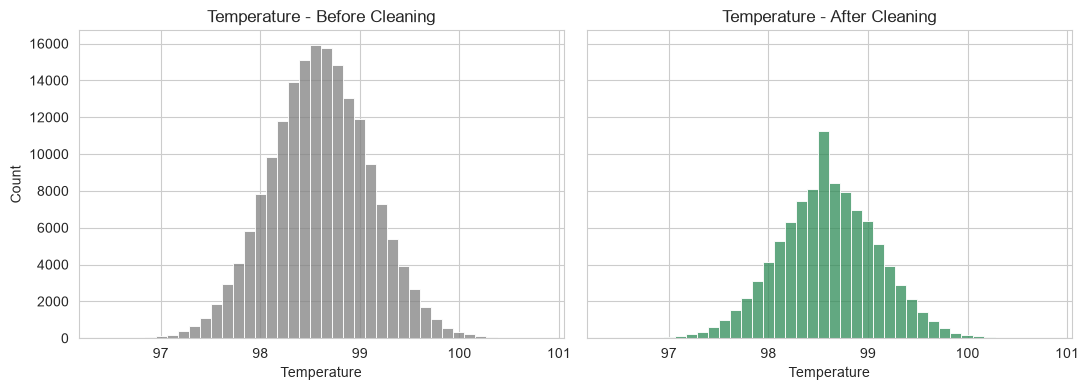

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
sns.histplot(raw["Temperature"].dropna(), bins=40, ax=ax[0], color="gray")
ax[0].set_title("Temperature - Before Cleaning")
sns.histplot(df["Temperature"], bins=40, ax=ax[1], color="seagreen")
ax[1].set_title("Temperature - After Cleaning")
plt.tight_layout()
plt.show()

**Observations:**
- Rows went from 200,000 to 98,976, which is exactly the number of unique students. Columns stay at 13.
- Null values went from 260,000 to 0, duplicate rows from 7,644 to 0, and repeated Student IDs from 81,024 to 0.
- Columns with a wrong data type went from 5 to 0.
- The Temperature histogram keeps the same overall bell shape after cleaning. A taller bar appears near 98.6 F, which is a side effect of median imputation: the missing values were all filled with the same number. This is a known limitation of median filling.

## 6. Save the Cleaned Dataset
The cleaned data is saved as cleaned_dataset.csv and reloaded to confirm that it is correct.

In [18]:
df.to_csv("cleaned_dataset.csv", index=False)

check = pd.read_csv("cleaned_dataset.csv")
print("Saved cleaned_dataset.csv with shape:", check.shape)
print("Null values in saved file:", check.isnull().sum().sum())

Saved cleaned_dataset.csv with shape: (98976, 13)
Null values in saved file: 0


## 7. Conclusion
The raw dataset had 10% missing values in every column, 7,644 exact duplicate rows, every student stored twice, and five columns with the wrong data type. After cleaning, the dataset contains 98,976 unique students with no missing values, no duplicates and correct data types.

**Key decisions:**
- Duplicates were handled in two stages: exact duplicates were removed, then the two rows of the same student were merged after checking that they never conflict.
- Missing values were recovered with the exact BMI formula wherever possible, then filled with the median (numeric) or "Unknown" (categorical).
- Outliers in Temperature and BMI were kept because they are medically plausible.

**Limitations:** median filling creates a small spike at the median, and the dataset had no inconsistent text formats or dates, so those cleaning steps found nothing to fix.